In [12]:
# Install packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt

#Set file paths
root_fldr = Path.cwd().parent
raw_fldr = root_fldr/"data"/"raw"
processed_fldr = root_fldr/'data'/'processed'
prescribed_burns_cleaned = gpd.read_file(processed_fldr / "prescribed_burns.gpkg")
inaturalist_gdf_cleaned = gpd.read_file(processed_fldr / "inaturalist_gdf_cleaned.gpkg")

In [13]:
#Check variable types and missing values
prescribed_burns_cleaned.info()
prescribed_burns_cleaned.isna().mean().sort_values()*100

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 8345 entries, 0 to 8344
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   year               8345 non-null   int64              
 1   agency             8345 non-null   str                
 2   burn_name          7000 non-null   str                
 3   treatment_type     8286 non-null   float64            
 4   start_date         7515 non-null   datetime64[ms, UTC]
 5   end_date           8071 non-null   datetime64[ms, UTC]
 6   acres_treated      7593 non-null   float64            
 7   gis_acres_treated  8343 non-null   float32            
 8   Shape_Length       8345 non-null   float64            
 9   Shape_Area         8345 non-null   float64            
 10  geometry           8345 non-null   geometry           
dtypes: datetime64[ms, UTC](2), float32(1), float64(4), geometry(1), int64(1), str(2)
memory usage: 684.7

year                  0.000000
agency                0.000000
Shape_Area            0.000000
Shape_Length          0.000000
geometry              0.000000
gis_acres_treated     0.023966
treatment_type        0.707010
end_date              3.283403
acres_treated         9.011384
start_date            9.946075
burn_name            16.117436
dtype: float64

In [14]:
#Check for duplicates in the prescribed burn dataset
prescribed_burns_cleaned.duplicated().sum()

np.int64(0)

Prescribed Fires Data Audit:
All data types are correct. We have missing data for gis acres treated, acres treated, burn name, start date, end date, and treatement type. However, all row entries have years and fire polygons, which are most important for analysis. Specific start date and end date are useful for getting better insight into the month and length of fires, but not necessarily vital for analysis. It would be interesting to look at the impacts of treatment type, but we will only be able to do this with ~85% of the records. We filtered out all duplicate entries in the cleaning process.

In [15]:
#Check variable types and missing values
inaturalist_gdf_cleaned.info()
inaturalist_gdf_cleaned.isna().mean().sort_values()*100

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 147426 entries, 0 to 147425
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                147426 non-null  int64         
 1   observation_date  147426 non-null  datetime64[ms]
 2   location          147230 non-null  str           
 3   scientific_name   147426 non-null  str           
 4   common_name       147426 non-null  str           
 5   geometry          147426 non-null  geometry      
dtypes: datetime64[ms](1), geometry(1), int64(1), str(3)
memory usage: 6.7 MB


id                  0.000000
observation_date    0.000000
scientific_name     0.000000
common_name         0.000000
geometry            0.000000
location            0.132948
dtype: float64

In [16]:
#Check for duplicates in the data
inaturalist_gdf_cleaned.duplicated().sum()

np.int64(0)

Invasives Audit: All data types are correct. Our processed dataset contains information for all invasive plant species across California. We selected the variables observation date, location name, scientific name, common name, and geometric point coordinate of the observation from our raw data set as the important variables needed for our analysis and remove columns that contain repeat of information. Only our selected column of location contains 196 missing values. This won't be an issue because we have geometric coordinate points for all rows in our data, and we can deduce the location from the geometric points. There are 960 duplicates within the data, but because they have unique id observations we're treating them as independent observations. It could be possible that two different users made the same observation on the same day at the same location. We'll need to check our raw data set to see if the duplicates occur with the same user ID. Overall, our processd data set contains all the information we need to start our analysis of where invasive species observations and prescribed burns overlap.

A join between these two datasets is not practical because they don't have matching columns and the rows represent entirely different things. For our main analysis, we plan to pull the geometries from both datasets separately to assess where they intersect (also taking date into consideration).

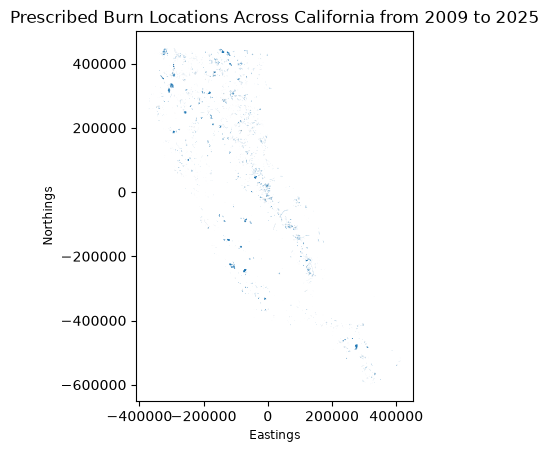

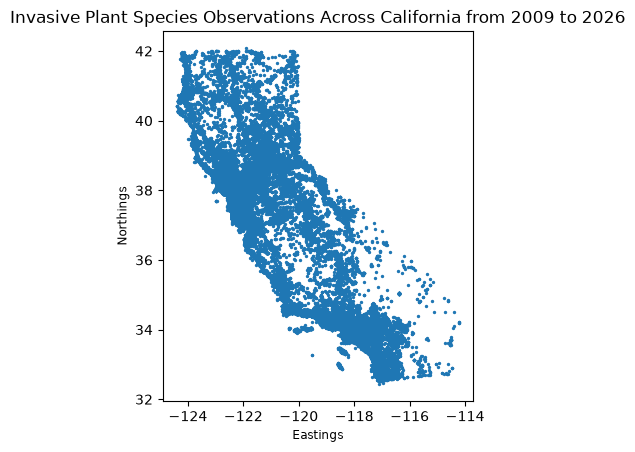

In [17]:
#Plot prescribed burns data
prescribed_burns_cleaned.plot();
plt.title("Prescribed Burn Locations Across California from 2009 to 2025")
plt.xlabel("Eastings");
plt.ylabel("Northings");

#Plot invasive plants observations data
inaturalist_gdf_cleaned.plot(markersize = 2);
plt.title("Invasive Plant Species Observations Across California from 2009 to 2026");
plt.xlabel("Eastings");
plt.ylabel("Northings");


Plot observations: The prescribed burns are scattered across California, with more occurrences spatially across Northern California. Overall, prescribed burns look to be controlled within a smaller area. The invasive plant species observations covers all most of California, with the majority of observations along the coast and across the strip from San Francisco to Lake Tahoe. The data coverage of this dataset is helpful when we filter through species observations for those within the prescribed burn polygons. 